In [7]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

B = "../data/lake/bronze" # ".." means one folder up from notebooks/
products = pd.read_csv(f"{B}/makeup_products.csv")
reviews = pd.read_csv(f"{B}/makeup_reviews.csv",low_memory=False)
print(len(products),len(reviews))

1373 314029


In [9]:
def profile(df):
 return pd.DataFrame({
 "dtype": df.dtypes.astype(str), # the kind of data
 "non-null":df.notna().sum(), # how many cells are filled
 "null_pct": (df.isna().mean() * 100).round(1), # % of cells that are empty
 "unique": df.nunique(), # how many different values
 "example": df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else
None),
 })

profile(reviews)

,dtype,non-null,null_pct,unique,example
unique_review_id,int64,314029,0.0,314029,1
product_link_id,int64,314029,0.0,1403,8
review_id,int64,314029,0.0,56999,521867580
type,object,314029,0.0,3,image
id,float64,261849,16.6,46082,521867563.0
ugc_id,float64,52180,83.4,25429,525372766.0
legacy_id,float64,52180,83.4,25429,402725357.0
internal_review_id,int64,314029,0.0,25430,-1
headline,object,314029,0.0,38626,2C3 Fresco
nickname,object,312730,0.4,31412,Dinara


In [10]:
print(products.columns.tolist())
print(reviews.columns.tolist())

['product_link_id', 'product_link', 'category', 'item_id', 'product_name', 'brand', 'price', 'num_shades', 'rating', 'num_reviews', 'description', 'pros', 'cons', 'best_uses', 'describe_yourself', 'review_star_1', 'review_star_2', 'review_star_3', 'review_star_4', 'review_star_5', 'rating_star_1', 'rating_star_2', 'rating_star_3', 'rating_star_4', 'rating_star_5', 'rating_count', 'review_count', 'average_rating', 'recommended_ratio', 'native_review_count', 'native_sampling_review_count', 'native_community_content_review_count', 'syndicated_review_count', 'faceoff_negative', 'faceoff_positive']
['unique_review_id', 'product_link_id', 'review_id', 'type', 'id', 'ugc_id', 'legacy_id', 'internal_review_id', 'headline', 'nickname', 'created_date', 'updated_date', 'rating', 'helpful_votes', 'not_helpful_votes', 'uri', 'comments', 'locale', 'location', 'bottom_line', 'product_page_id', 'upc', 'gtin', 'is_staff_reviewer', 'is_verified_buyer', 'is_verified_reviewer', 'helpful_score']


In [11]:
checks = {

    # PRODUCTS DATASET

    "products: duplicate rows":
        products.duplicated().sum(),

    "products: duplicate product_link_id":
        products["product_link_id"].duplicated().sum(),

    "products: missing brand":
        products["brand"].isna().sum(),

    "products: missing category":
        products["category"].isna().sum(),

    "products: missing price":
        products["price"].isna().sum(),

    "products: invalid price <= 0":
        (products["price"] <= 0).sum(),

    "products: missing rating":
        products["rating"].isna().sum(),

    "products: invalid rating (<0 or >5)":
        ((products["rating"] < 0) | (products["rating"] > 5)).sum(),

    # REVIEWS DATASET

    "reviews: duplicate rows":
        reviews.duplicated().sum(),

    "reviews: duplicate review_id":
        reviews["review_id"].duplicated().sum(),

    "reviews: missing nickname":
        reviews["nickname"].isna().sum(),

    "reviews: missing headline":
        reviews["headline"].isna().sum(),

    "reviews: missing comments":
        reviews["comments"].isna().sum(),

    "reviews: missing rating":
        reviews["rating"].isna().sum(),

    "reviews: invalid rating (<1 or >5)":
        ((reviews["rating"] < 1) | (reviews["rating"] > 5)).sum(),

    # REFERENTIAL INTEGRITY

    "reviews: unknown product_link_id":
        (~reviews["product_link_id"].isin(products["product_link_id"])).sum(),

    # POSSIBLE PII RISKS

    "reviews: nickname present":
        reviews["nickname"].notna().sum(),

    "reviews: email in comments":
        reviews["comments"].astype(str).str.contains(
            r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}",
            na=False
        ).sum(),

    "reviews: phone number in comments":
        reviews["comments"].astype(str).str.contains(
            r"01\d-?\d{7,8}|\+60\d+",
            na=False
        ).sum(),

}

pd.Series(checks, name="issues").to_frame()

,issues
products: duplicate rows,0
products: duplicate product_link_id,0
products: missing brand,443
products: missing category,22
products: missing price,0
products: invalid price <= 0,0
products: missing rating,141
products: invalid rating (<0 or >5),0
reviews: duplicate rows,0
reviews: duplicate review_id,257030


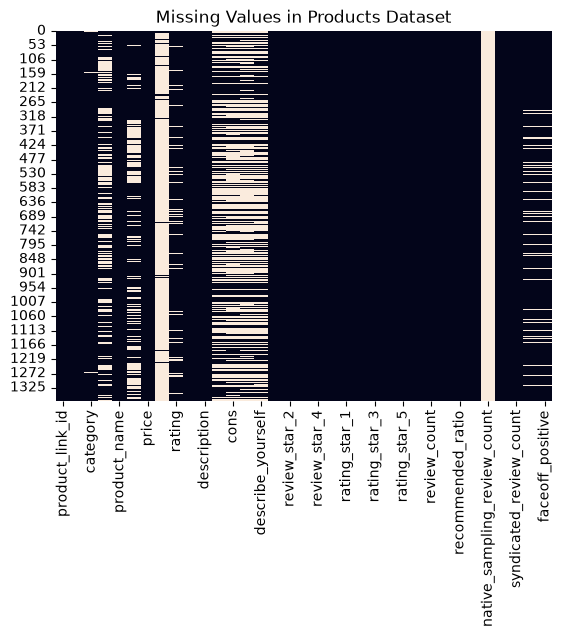

In [12]:
sns.heatmap(products.isnull(), cbar=False)
plt.title("Missing Values in Products Dataset")
plt.show()

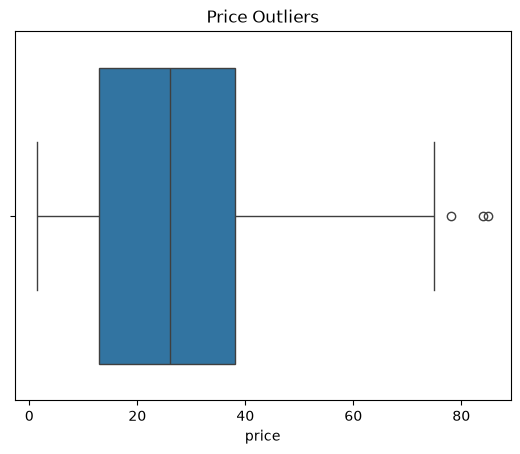

In [13]:
sns.boxplot(x=products["price"])
plt.title("Price Outliers")
plt.show()

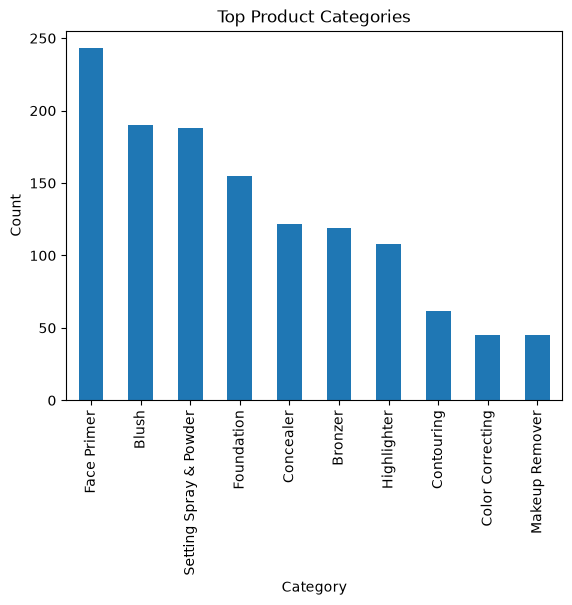

In [14]:
products["category"].value_counts().head(10).plot(
kind="bar"
)
plt.title("Top Product Categories")
plt.xlabel("Category")
plt.ylabel("Count")
plt.show()